# RetailMind AI — Day 8: background removal and Grad-CAM

Cut the product out of its picture (OpenCV), explain the CNN's decision (Grad-CAM), and use both through one object, `CatalogVision`. This notebook runs the module live.

In [1]:
# Work from the project root so the `src` package can be imported
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, ROOT)
print("project folder:", os.path.basename(ROOT))

project folder: day3-4


## 1. Load the module and four test pictures

In [2]:
from src.train_day6 import load_fashion_mnist, FASHION_CLASSES
from src.vision import CatalogVision

_, _, x_test, y_test = load_fashion_mnist()
pictures = (x_test[:4, :, :, 0] * 255).astype("uint8")
vision = CatalogVision()
print("ready; categories:", len(FASHION_CLASSES))

ready; categories: 10


## 2. Analyse each picture: category, mask, clean picture, heatmap

In [3]:
for picture, real in zip(pictures, y_test[:4]):
    result = vision.analyze(picture)
    print("real:", FASHION_CLASSES[int(real)], "| predicted:", result["category"], result["confidence"],
          "| product covers", result["product_share"], "of the picture | heat on product:", result["heat_on_product"])

real: Ankle boot | predicted: Ankle boot 1.0 | product covers 0.311 of the picture | heat on product: 0.67
real: Pullover | predicted: Pullover 1.0 | product covers 0.64 of the picture | heat on product: 0.832
real: Trouser | predicted: Trouser 1.0 | product covers 0.321 of the picture | heat on product: 0.004
real: Trouser | predicted: Trouser 1.0 | product covers 0.309 of the picture | heat on product: 0.001


## 3. What it looks like

Each column is one picture. Rows: **original, mask, product on white, Grad-CAM**. Green title = correct answer.

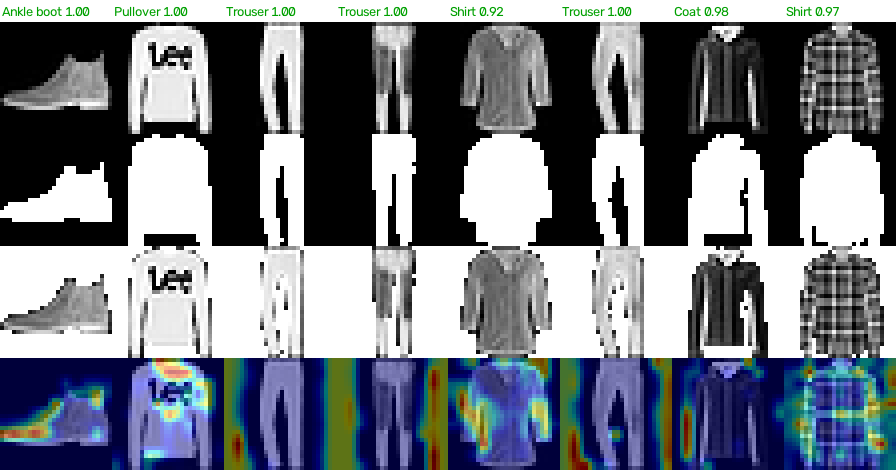

In [4]:
from IPython.display import Image, display
display(Image("reports/day8_catalog_grid.png"))

## 4. The numbers over 1,000 test pictures (from `python -m src.run_day8`)

In [5]:
import json
day8 = json.load(open("models/day8_results.json"))
for key, value in day8.items():
    if key != "photo_demo":
        print(f"{key:<42}{value}")

pictures_checked                          1000
accuracy_original                         0.914
accuracy_background_removed_on_black      0.911
accuracy_background_removed_on_white      0.34
same_answer_after_cleaning_on_black       0.996
mask_share_of_picture_mean                0.483
empty_masks                               0
heat_on_product_mean                      0.468
heat_on_product_when_right                0.466
heat_on_product_when_wrong                0.483
wrong_answers                             86


## 5. A colour photo

GrabCut inside a box from the Day 7 detector, on a public sample photo (not a product).

{'box_label': 'bus', 'output': 'reports/day8_photo_cutout.jpg', 'note': 'GrabCut inside the saved YOLO box on the Ultralytics sample photo; not a catalog image'}


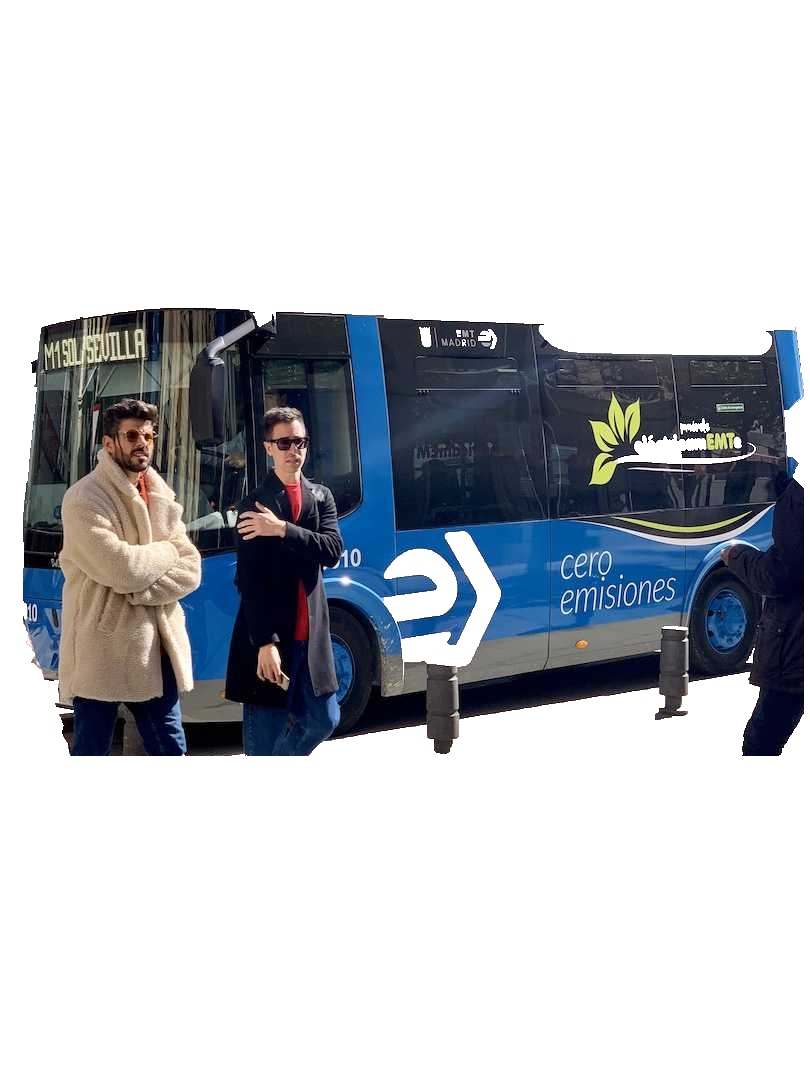

In [6]:
print(day8["photo_demo"])
display(Image("reports/day8_photo_cutout.jpg", width=360))

## 6. Conclusion

- **Background removal kept the answers:** accuracy 0.914 on the originals and 0.911 after cleaning (99.6% same answers). This is an easy case, because these pictures already have a flat black background.
- **Classify first, composite last.** On a white background the CNN falls to 0.340, so the white version is only for publishing.
- **Grad-CAM does not prove the model looks at the product.** The heat on the product (0.468) is about the product's share of the picture (0.483). For trousers it lights up the space beside the legs, so it shows where the evidence is, not that the answer is right.
- **Not done:** a learned segmenter (no masks to train on) and real catalog photos (the Kaggle set needs an account).
- One run, the first 1,000 test pictures.